::: {.sb-downloads}
[Download this notebook](../downloads/solutions-stars-and-galaxies.ipynb){download="solutions-stars-and-galaxies.ipynb"}  
Data: [sdss_skyserver.csv](../downloads/data/sdss_skyserver.csv){download="sdss_skyserver.csv"}

Put the data files in a folder named `data` next to the notebook.
:::

::: {.sb-lesson-links}
[← Back to the exercises](../exercises/stars-and-galaxies.ipynb)
:::

::: {.callout-tip}
Try the exercises on your own first: you learn much more by searching than by reading a solution.
:::

The [Sloan Digital Sky Survey](https://www.sdss.org/) (SDSS) maps the sky with a 2.5 m telescope in New Mexico. Its camera takes images through five filters, from ultraviolet to infrared: **u, g, r, i, z**. For some of the objects, a spectrograph also measures a spectrum, from which astronomers get the **class** of the object (star, galaxy or quasar) and its **redshift** (how much its light is shifted to the red, which tells how far away it is).

Images are cheap: the SDSS has photographed hundreds of millions of objects. Spectra are expensive: only a small fraction of them have one. **Can we tell stars, galaxies and quasars apart from the images alone?** That's the question of this exercise, and a perfect playground for boosting.

## The data {#ex-the-data}
`../data/sdss_skyserver.csv` contains 10,000 objects of the SDSS (Data Release 14) with a spectrum:

* `u`, `g`, `r`, `i`, `z`: the brightness in each filter, as a *magnitude* (the higher the magnitude, the fainter the object);
* `ra`, `dec`: the position in the sky;
* `redshift`: measured on the spectrum;
* `class`: `STAR`, `GALAXY` or `QSO` (quasar), the target;
* technical columns: identifiers (`objid`, `specobjid`), the image (`run`, `rerun`, `camcol`, `field`) and the spectrum (`plate`, `mjd`, `fiberid`).

In [ ]:
import time
import pandas as pd
import numpy as np
import plotly.express as px

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from xgboost import XGBClassifier

import plotly.io as pio
import plotly.graph_objects as go
# colour palette of the course
pio.templates["course"] = go.layout.Template(
    layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
)
pio.templates.default = "plotly_white+course"

## Exploration {#ex-exploration}

1. Load the data. How many objects of each class are there?

In [ ]:
sdss = pd.read_csv("../data/sdss_skyserver.csv")
print(sdss.shape)
sdss["class"].value_counts()

(10000, 18)


class
GALAXY    4998
STAR      4152
QSO        850
Name: count, dtype: int64

**Half of the objects are galaxies, 40% are stars and less than 10% are quasars.**

2. Compare the redshift of the three classes (a box plot, or `groupby` and `describe`). What do you notice?

In [ ]:
print(sdss.groupby("class")["redshift"].describe().round(3))
fig = px.box(sdss, x="class", y="redshift", title="Redshift by class")
fig.show()

         count   mean    std    min    25%    50%    75%    max
class                                                          
GALAXY  4998.0  0.080  0.046 -0.001  0.051  0.077  0.101  0.856
QSO      850.0  1.218  0.698  0.000  0.651  1.234  1.745  5.354
STAR    4152.0  0.000  0.000 -0.004 -0.000  0.000  0.000  0.005


**The redshift almost gives the answer: stars are in our galaxy (redshift ≈ 0), galaxies are further away (≈ 0.08), and quasars are very distant (≈ 1.2). A model with the redshift would be almost perfect, but the redshift needs a spectrum: in this exercise, we only use what the images tell us.**

3. Keep only the five magnitudes `u`, `g`, `r`, `i`, `z` as features. Why should we also leave out `plate`, `mjd` and `fiberid`?

Encode the target with a `LabelEncoder`, and split the data (25% for the test set, stratified).

In [ ]:
features = ["u", "g", "r", "i", "z"]
X = sdss[features]
encoder = LabelEncoder()
y = encoder.fit_transform(sdss["class"])
print("Classes:", list(encoder.classes_))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

Classes: ['GALAXY', 'QSO', 'STAR']


**`plate`, `mjd` and `fiberid` describe how the spectrum was recorded (which plate, which night, which fibre). They don't describe the object itself, and they would not exist for an object without a spectrum, which is exactly what we want to classify. Using them would be a form of data leakage.**

## From one tree to boosting {#ex-from-one-tree-to-boosting}

4. Train and compare the following models: a decision tree (`max_depth=5`), AdaBoost (on trees of depth 3, 200 estimators), scikit-learn's gradient boosting, and XGBoost (300 estimators, `max_depth=4`). For each one, print the accuracy on the train and test sets and the training time.

In [ ]:
models = {
    "Decision tree": DecisionTreeClassifier(max_depth=5, random_state=0),
    "AdaBoost": AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=200, random_state=0),
    "Gradient boosting": GradientBoostingClassifier(random_state=0),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, random_state=0),
}


def compare(models, X_train, X_test):
    rows = []
    for name, model in models.items():
        start = time.perf_counter()
        model.fit(X_train, y_train)
        rows.append({"model": name, "train accuracy": model.score(X_train, y_train),
                     "test accuracy": model.score(X_test, y_test), "training time (s)": time.perf_counter() - start})
    return pd.DataFrame(rows).round(3)


compare(models, X_train, X_test)

,model,train accuracy,test accuracy,training time (s)
0,Decision tree,0.788,0.772,0.036
1,AdaBoost,0.891,0.868,2.869
2,Gradient boosting,0.923,0.889,3.276
3,XGBoost,0.972,0.920,0.740


**A single tree classifies about 3 objects out of 4 correctly. Each boosting method does much better, and XGBoost is both the most accurate and one of the fastest: boosting combines many weak trees, each one correcting the errors of the previous ones.**

## Feature engineering: colours {#ex-feature-engineering-colours}
Astronomers rarely use the magnitudes alone. They use **colours**: the difference between two magnitudes, like `u - g`. A colour does not depend on the distance or the size of the object, only on the shape of its light spectrum: it says *what kind* of object it is, not how bright it looks.

5. Add the four colours `u-g`, `g-r`, `r-i` and `i-z` to the features, and compare the models again.

In [ ]:
for a, b in [("u", "g"), ("g", "r"), ("r", "i"), ("i", "z")]:
    sdss[f"{a}-{b}"] = sdss[a] - sdss[b]

features_colours = features + ["u-g", "g-r", "r-i", "i-z"]
X_train, X_test, y_train, y_test = train_test_split(sdss[features_colours], y, test_size=0.25, stratify=y, random_state=0)

compare(models, X_train, X_test)

,model,train accuracy,test accuracy,training time (s)
0,Decision tree,0.960,0.942,0.046
1,AdaBoost,0.964,0.945,4.733
2,Gradient boosting,0.979,0.959,5.603
3,XGBoost,0.997,0.967,0.836


6. Plot the colour `u-g` against the colour `g-r` for a sample of objects, coloured by class.

In [ ]:
fig = px.scatter(sdss.sample(3000, random_state=0), x="u-g", y="g-r", color="class", opacity=0.6,
                 range_x=[-0.5, 4], range_y=[-0.5, 2.5], title="Colour-colour diagram")
fig.show()

**With the colours, even a single tree gets above 90%: the three classes occupy different regions of the colour-colour diagram (quasars are bluer, with a small `u-g`). Good features matter as much as a good model, and boosting still adds a few points on top.**

## Evaluating the best model {#ex-evaluating-the-best-model}

7. For XGBoost, print the classification report and the confusion matrix on the test set. Which class is the hardest to recognise? Why?

              precision    recall  f1-score   support

      GALAXY      0.980     0.963     0.972      1250
         QSO      0.946     0.901     0.923       212
        STAR      0.956     0.986     0.971      1038

    accuracy                          0.967      2500
   macro avg      0.961     0.950     0.955      2500
weighted avg      0.967     0.967     0.967      2500



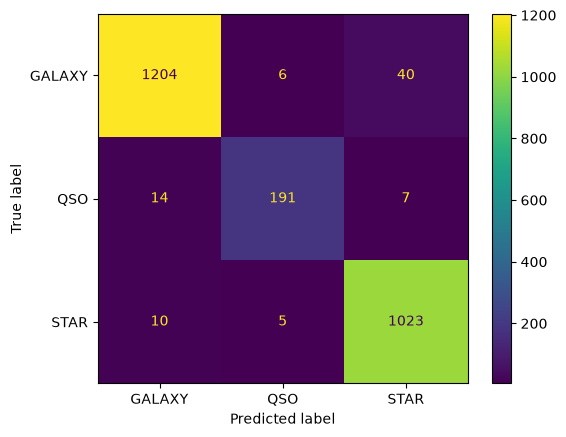

In [ ]:
xgb = models["XGBoost"]  # already trained on the features with colours
y_pred = xgb.predict(X_test)
print(classification_report(y_test, y_pred, target_names=encoder.classes_, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=encoder.classes_);

**Quasars have the lowest recall: they are the rarest class (less than 10% of the training examples), and some look like stars on images, as both are point-like sources.**

8. Use a 5-fold cross-validation to check that the score of XGBoost is not a lucky split. Then plot its feature importances.

In [ ]:
scores = cross_val_score(XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, random_state=0),
                         sdss[features_colours], y, cv=5)
print("Accuracy per fold:", scores.round(3))
print(f"Mean: {scores.mean():.3f} ± {scores.std():.3f}")

importances = pd.Series(xgb.feature_importances_, index=features_colours).sort_values()
fig = px.bar(x=importances.values, y=importances.index, orientation="h", title="XGBoost feature importances",
             labels={"x": "importance", "y": ""})
fig.show()

Accuracy per fold: [0.964 0.966 0.973 0.967 0.971]
Mean: 0.968 ± 0.003


**The cross-validated accuracy is stable across the folds. The four colours are the most important features, far ahead of the magnitudes.**

## Conclusion {#ex-conclusion}

* From the five magnitudes alone, a single decision tree is not good enough, and **boosting** gains more than 10 points of accuracy.
* **Feature engineering based on domain knowledge** (colours) gains even more, for all the models.
* The best model classifies about 97% of the objects correctly from their images only: it could pre-classify the millions of objects that have no spectrum.